In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pit
import seaborn as sns

print("libraries loaded successfully!")

libraries loaded successfully!


In [2]:
df = pd.read_csv('../survey.csv')
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [3]:
print("number of rows:", df.shape[0])
print("number of columns:",df.shape[1])
print()

df.info()

number of rows: 1259
number of columns: 27

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Timestamp                  1259 non-null   object
 1   Age                        1259 non-null   int64 
 2   Gender                     1259 non-null   object
 3   Country                    1259 non-null   object
 4   state                      744 non-null    object
 5   self_employed              1241 non-null   object
 6   family_history             1259 non-null   object
 7   treatment                  1259 non-null   object
 8   work_interfere             995 non-null    object
 9   no_employees               1259 non-null   object
 10  remote_work                1259 non-null   object
 11  tech_company               1259 non-null   object
 12  benefits                   1259 non-null   object
 13  care_options       

In [4]:
df.describe()

,Age
count,1.259000e+03
mean,7.942815e+07
std,2.818299e+09
min,-1.726000e+03
25%,2.700000e+01
50%,3.100000e+01
75%,3.600000e+01
max,1.000000e+11


In [5]:
df['Age'].value_counts().sort_index().head(20)

Age
-1726     1
-29       1
-1        1
 5        1
 8        1
 11       1
 18       7
 19       9
 20       6
 21      16
 22      21
 23      51
 24      46
 25      61
 26      75
 27      71
 28      68
 29      85
 30      63
 31      67
Name: count, dtype: int64

In [6]:
df_clean =df[(df['Age'] >=18) & (df['Age'] <= 100)].copy()

print("original rows:", len(df))
print("after cleaning:", len(df_clean))
print("removed rows:", len(df) - len(df_clean))

original rows: 1259
after cleaning: 1251
removed rows: 8


In [7]:
df_clean['Gender'].value_counts()

Gender
Male                                              612
male                                              204
Female                                            121
M                                                 116
female                                             62
F                                                  38
m                                                  34
f                                                  15
Make                                                4
Woman                                               3
Male                                                3
Female                                              2
Cis Male                                            2
Man                                                 2
Female (trans)                                      2
Malr                                                1
Trans woman                                         1
male leaning androgynous                            1
Cis Man              

In [8]:
df_clean['Gender'] = df_clean['Gender'].str.lower()
df_clean['Gender'].value_counts().head(20)

Gender
male                        816
female                      183
m                           150
f                            53
woman                         4
make                          4
male                          3
cis male                      3
female                        2
man                           2
female (trans)                2
msle                          1
male leaning androgynous      1
trans woman                   1
queer                         1
neuter                        1
cis-female/femme              1
female (cis)                  1
mail                          1
malr                          1
Name: count, dtype: int64

In [9]:
def clean_gender(value):
    value = str(value).strip().lower()
    if value in ['male', 'm', 'man', 'male-ish' , 'msle' , 'maile' , 'mal' , 'make' , 'cis male' , 'malr', 'mail']:
        return 'Male'
    elif value in ['female', 'f','woman', 'femake', 'cis female' 'female (cis)', 'female (trans)', 'trans woman', 'cis-female/femme']:
        return 'Female'
    else:
        return'Other'
df_clean['Gender']= df_clean['Gender'].apply(clean_gender)
df_clean['Gender'].value_counts()
        

Gender
Male      984
Female    247
Other      20
Name: count, dtype: int64

In [10]:
df_clean.to_csv('cleaned_survey.csv' , index=False)
print("Saved successfully!")

Saved successfully!


In [11]:
df_clean.isnull().sum()

Timestamp                       0
Age                             0
Gender                          0
Country                         0
state                         513
self_employed                  18
family_history                  0
treatment                       0
work_interfere                262
no_employees                    0
remote_work                     0
tech_company                    0
benefits                        0
care_options                    0
wellness_program                0
seek_help                       0
anonymity                       0
leave                           0
mental_health_consequence       0
phys_health_consequence         0
coworkers                       0
supervisor                      0
mental_health_interview         0
phys_health_interview           0
mental_vs_physical              0
obs_consequence                 0
comments                     1090
dtype: int64

In [12]:
df_clean = df_clean.drop(columns=['comments', 'state'])
df_clean['work_interfere']= df_clean['work_interfere'].fillna('Unknown')
df_clean['self_employed'] = df_clean['self_employed'].fillna('No')
df_clean.isnull().sum().sum()

np.int64(0)

In [13]:
df_clean['treatment'].value_counts()

treatment
Yes    632
No     619
Name: count, dtype: int64

In [14]:
import matplotlib.pyplot as plt

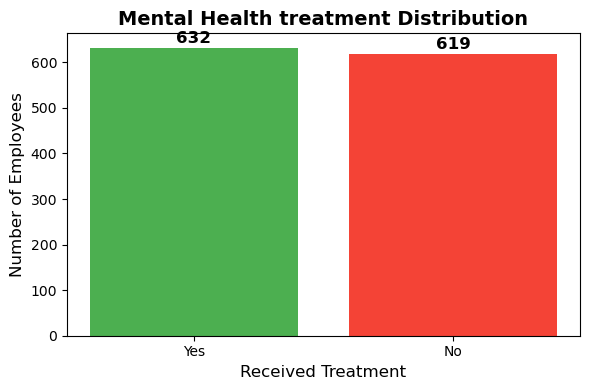

In [18]:
treatment_counts = df_clean['treatment'].value_counts()

plt.figure(figsize=(6,4))
plt.bar(treatment_counts.index,treatment_counts.values,color=['#4CAF50','#F44336'])
plt.title('Mental Health treatment Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Received Treatment', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
for i, v in enumerate(treatment_counts.values):
    plt.text(i, v+10, str(v), ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()    
plt.show()


treatment   No  Yes
Gender             
Female      75  172
Male       537  447
Other        7   13


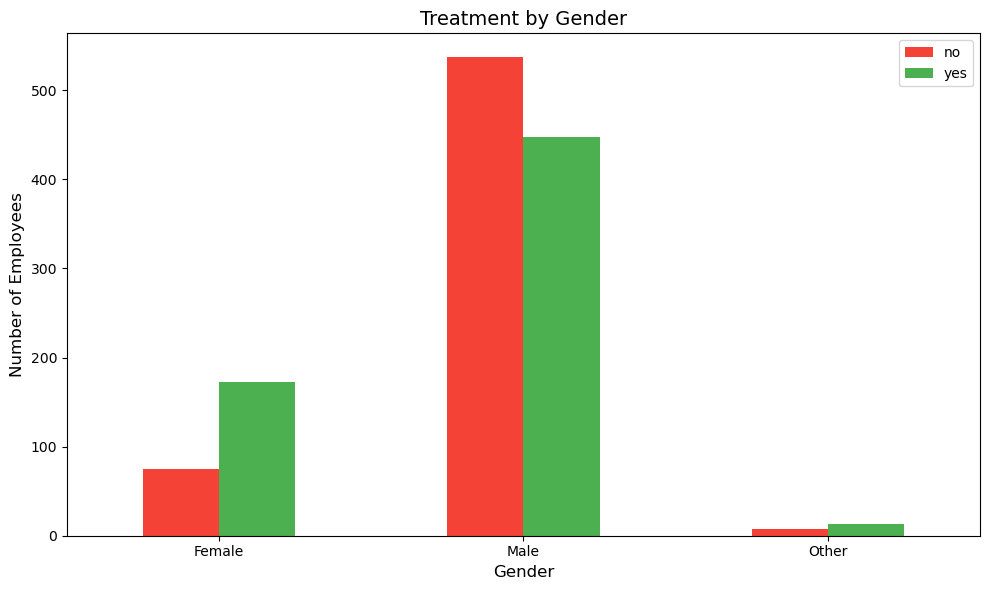

In [16]:
gender_treatment = pd.crosstab(df_clean['Gender'],df_clean['treatment'])
print(gender_treatment)
ax = gender_treatment.plot(kind='bar',figsize=(10,6), color=['#F44336', '#4caf50'])
ax.set_title('Treatment by Gender', fontsize=14)
ax.set_xlabel('Gender', fontsize=12)
ax.set_ylabel('Number of Employees', fontsize=12)
plt.xticks(rotation=0)
ax.legend(['no', 'yes'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
import matplotlib.pyplot as plt
plt.savefig('../images/treatment_by_gender.png', dpi=100, bbox_inches='tight')
print("chart saved!")

chart saved!


<Figure size 640x480 with 0 Axes>